# Problem Statement: E-Commerce Shopper Behaviour Analysis

- Analyse customer demographics and shopping preferences.
- Identify patterns in purchasing behaviour.
- Understand factors influencing customer purchase decisions.
- Explore relationships between customer attributes and shopping habits.
- Identify trends through Exploratory Data Analysis (EDA).
- Derive meaningful insights to support better e-commerce business decisions.

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings('ignore')

In [7]:
df = pd.read_excel('e_commerce_shopper_behaviour_and_lifestyle.xlsx')

df.to_csv('e_commerce_shopper_behaviour_and_lifestyle.csv', index=False)

In [8]:
df = pd.read_csv('e_commerce_shopper_behaviour_and_lifestyle.csv')

In [9]:
df.head()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,...,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
0,1,56,Female,Germany,Suburban,90860,Self-employed,Associate Degree,Single,0,...,10,2,62,7,74,19,2025-06-22,6,1,50
1,2,69,Male,Japan,Suburban,35423,Unemployed,Bachelor,Single,1,...,5,7,54,5,23,8,2026-07-25,3,0,37
2,3,46,Female,India,Urban,21467,Self-employed,Associate Degree,Married,1,...,3,3,33,7,12,13,2026-02-26,6,0,53
3,4,32,Male,Canada,Urban,41770,Self-employed,Bachelor,Widowed,0,...,5,9,26,4,19,9,2026-10-27,7,0,98
4,5,60,Female,Japan,Urban,183882,Employed,Associate Degree,Widowed,1,...,8,0,18,7,30,3,2026-06-23,3,0,86


In [10]:
df.tail()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,...,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
999995,999996,36,Female,France,Urban,192880,Student,Master,In a relationship,0,...,4,3,26,2,50,21,2025-06-27,2,1,93
999996,999997,37,Male,Canada,Urban,197111,Unemployed,Master,Divorced,0,...,10,9,31,5,78,15,2025-06-05,7,1,97
999997,999998,71,Male,UK,Urban,171275,Unemployed,Bachelor,Married,1,...,6,5,19,7,8,16,2026-09-25,5,0,96
999998,999999,30,Female,Germany,Urban,124983,Employed,High School,Single,0,...,4,2,56,5,8,11,2026-10-25,2,0,46
999999,1000000,61,Male,China,Rural,65396,Student,Bachelor,In a relationship,1,...,10,10,79,0,64,1,2025-12-17,5,0,43


In [11]:
df.shape

(1000000, 60)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 60 columns):
 #   Column                           Non-Null Count    Dtype
---  ------                           --------------    -----
 0   user_id                          1000000 non-null  int64
 1   age                              1000000 non-null  int64
 2   gender                           1000000 non-null  str  
 3   country                          1000000 non-null  str  
 4   urban_rural                      1000000 non-null  str  
 5   income_level                     1000000 non-null  int64
 6   employment_status                1000000 non-null  str  
 7   education_level                  1000000 non-null  str  
 8   relationship_status              1000000 non-null  str  
 9   has_children                     1000000 non-null  int64
 10  household_size                   1000000 non-null  int64
 11  occupation                       1000000 non-null  str  
 12  ethnicity                 

In [13]:
df.describe()

,user_id,age,income_level,has_children,household_size,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,...,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,social_sharing_frequency,premium_subscription,return_rate
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,500000.500000,49.003377,104994.565463,0.399426,5.505323,9.993011,2498.775654,40.212257,3.450584,255.031632,...,9.99766,5.494336,4.997523,50.001442,3.498840,49.989012,12.509560,3.593763,0.359415,50.004949
std,288675.278932,18.193959,54851.476652,0.489781,2.873725,6.055124,1444.208674,25.433343,1.856725,141.708466,...,6.05453,2.870467,3.162831,29.163437,2.291567,29.151948,6.922197,1.932566,0.479829,29.159616
min,1.000000,18.000000,10000.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,10.000000,...,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,250000.750000,33.000000,57466.000000,0.000000,3.000000,5.000000,1249.000000,18.000000,2.000000,132.000000,...,5.00000,3.000000,2.000000,25.000000,1.000000,25.000000,7.000000,2.000000,0.000000,25.000000
50%,500000.500000,49.000000,105013.000000,0.000000,6.000000,10.000000,2498.000000,40.000000,3.000000,255.000000,...,10.00000,5.000000,5.000000,50.000000,3.000000,50.000000,13.000000,4.000000,0.000000,50.000000
75%,750000.250000,65.000000,152497.000000,1.000000,8.000000,15.000000,3750.000000,62.000000,5.000000,378.000000,...,15.00000,8.000000,8.000000,75.000000,6.000000,75.000000,19.000000,5.000000,1.000000,75.000000
max,1000000.000000,80.000000,200000.000000,1.000000,10.000000,20.000000,5000.000000,90.000000,8.000000,500.000000,...,20.00000,10.000000,10.000000,100.000000,7.000000,100.000000,24.000000,8.000000,1.000000,100.000000


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.dtypes

user_id                            int64
age                                int64
gender                               str
country                              str
urban_rural                          str
income_level                       int64
employment_status                    str
education_level                      str
relationship_status                  str
has_children                       int64
household_size                     int64
occupation                           str
ethnicity                            str
language_preference                  str
device_type                          str
weekly_purchases                   int64
monthly_spend                      int64
cart_abandonment_rate              int64
review_writing_frequency           int64
average_order_value                int64
preferred_payment_method             str
coupon_usage_frequency             int64
loyalty_program_member             int64
referral_count                     int64
product_category

# 1. Univariate Analysis

Univariate analysis focuses on examining individual variables to understand their distributions, central tendencies, spread, and anomalies.

### Objectives:
- Analyse income level and monthly spending distributions.
- Examine daily session time and product views.
- Investigate cart abandonment and return rates.
- Explore demographic distributions across device type, country, education level, and employment status.

### 1.1 Income Level & Spending Distribution

- Examine the distribution of income levels and monthly spending across users.
- Identify spending patterns and variations.
- Determine whether monthly spending is heavily right-skewed.
- Identify potential high-spending outliers.

In [16]:
df[['income_level', 'monthly_spend']].describe()

,income_level,monthly_spend
count,1000000.000000,1000000.000000
mean,104994.565463,2498.775654
std,54851.476652,1444.208674
min,10000.000000,0.000000
25%,57466.000000,1249.000000
50%,105013.000000,2498.000000
75%,152497.000000,3750.000000
max,200000.000000,5000.000000


In [17]:
df[['income_level', 'monthly_spend']].skew()

income_level    -0.000053
monthly_spend    0.001212
dtype: float64

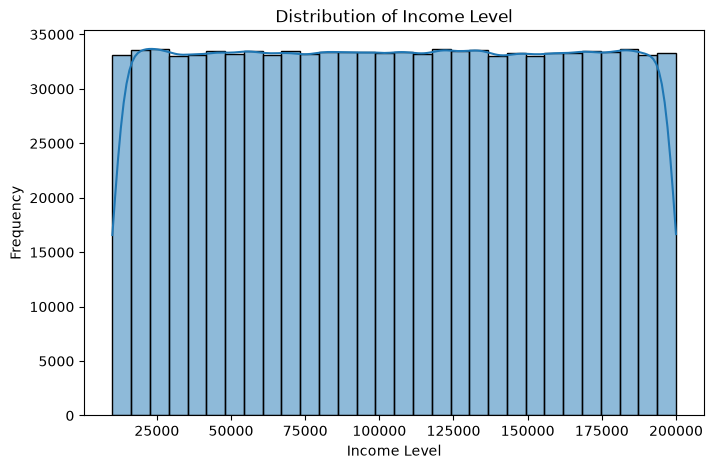

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df['income_level'], kde=True, bins=30)
plt.title('Distribution of Income Level')
plt.xlabel('Income Level')
plt.ylabel('Frequency')
plt.show()

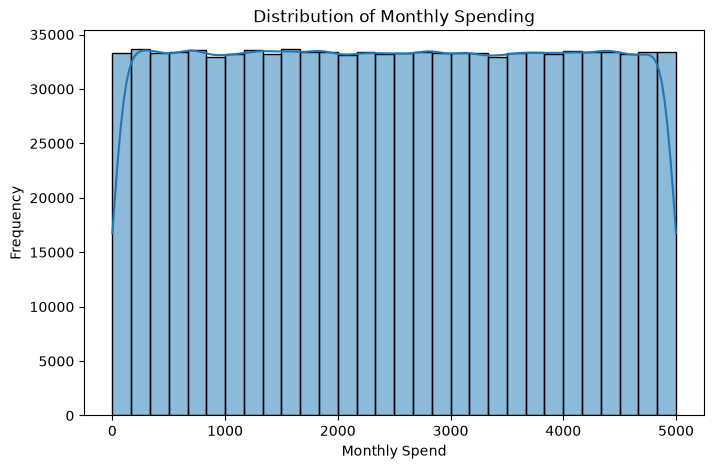

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df['monthly_spend'], kde=True, bins=30)
plt.title('Distribution of Monthly Spending')
plt.xlabel('Monthly Spend')
plt.ylabel('Frequency')
plt.show()

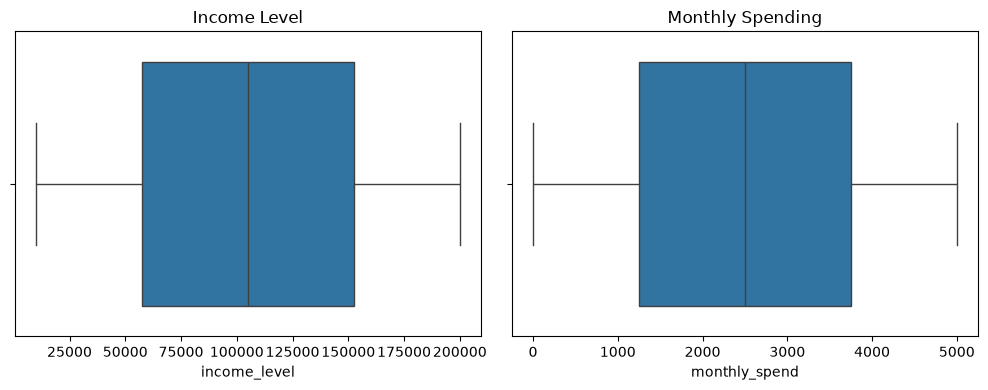

In [20]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['income_level'])
plt.title('Income Level')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['monthly_spend'])
plt.title('Monthly Spending')

plt.tight_layout()
plt.show()

In [21]:
df['monthly_spend'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.25    1249.0
0.50    2498.0
0.75    3750.0
0.90    4499.0
0.95    4751.0
0.99    4951.0
Name: monthly_spend, dtype: float64

### Conclusion

- Both income level and monthly spending show nearly symmetrical distributions.
- Monthly spending has negligible positive skewness (0.0012).
- The mean (2498.78) and median (2498) are almost identical.
- No significant right-skewness towards high-spending customers is observed.

### 1.2 Engagement Baselines

- Examine the distribution of daily session time and product views per day.
- Identify common user engagement patterns.
- Determine whether users prefer quick browsing sessions or extended platform engagement.
- Understand the overall level of platform interaction.

In [22]:
df[['daily_session_time_minutes', 'product_views_per_day']].describe()

,daily_session_time_minutes,product_views_per_day
count,1000000.000000,1000000.000000
mean,60.014414,25.018014
std,34.939233,14.721810
min,0.000000,0.000000
25%,30.000000,12.000000
50%,60.000000,25.000000
75%,90.000000,38.000000
max,120.000000,50.000000


In [23]:
df[['daily_session_time_minutes', 'product_views_per_day']].skew()

daily_session_time_minutes   -0.001709
product_views_per_day        -0.001492
dtype: float64

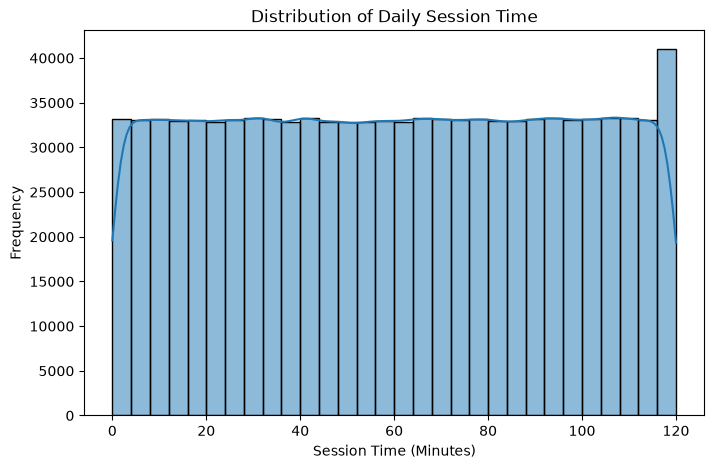

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(df['daily_session_time_minutes'], bins=30, kde=True)
plt.title('Distribution of Daily Session Time')
plt.xlabel('Session Time (Minutes)')
plt.ylabel('Frequency')
plt.show()


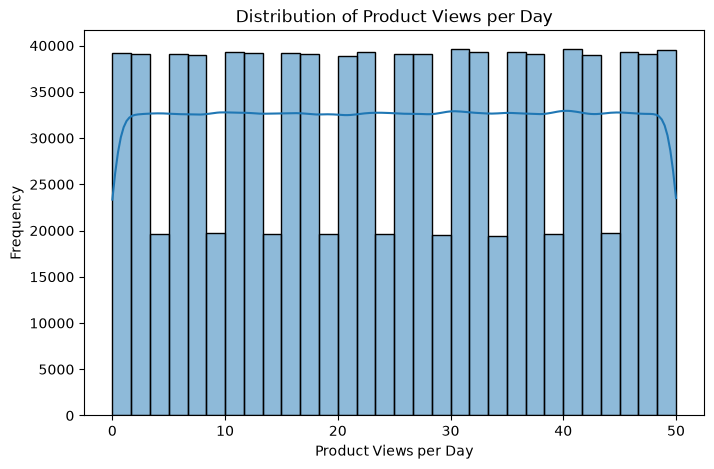

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(df['product_views_per_day'], bins=30, kde=True)
plt.title('Distribution of Product Views per Day')
plt.xlabel('Product Views per Day')
plt.ylabel('Frequency')
plt.show()

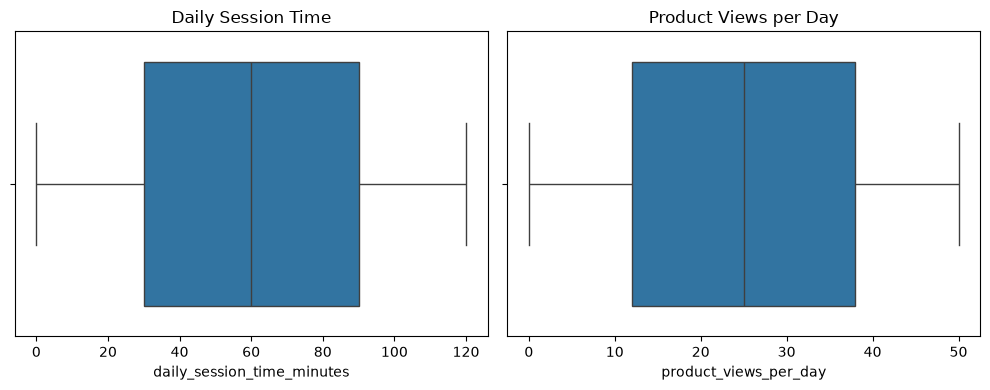

In [26]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['daily_session_time_minutes'])
plt.title('Daily Session Time')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['product_views_per_day'])
plt.title('Product Views per Day')

plt.tight_layout()
plt.show()

In [27]:
df[['daily_session_time_minutes', 'product_views_per_day']].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,daily_session_time_minutes,product_views_per_day
0.25,30.0,12.0
0.50,60.0,25.0
0.75,90.0,38.0
0.90,108.0,45.0
0.95,114.0,48.0
0.99,119.0,50.0


### Conclusion

- Average daily session time is approximately 60 minutes, with a median of 60 minutes.
- Users view an average of 25 products per day.
- Both variables show negligible negative skewness.
- Session time ranges from 0 to 120 minutes, while product views range from 0 to 50.
- The distributions indicate balanced engagement patterns across users.

### 1.3 Friction Metrics

- Examine the distribution of cart abandonment rates and return rates.
- Understand the typical level of shopping friction among users.
- Identify users with extremely high cart abandonment rates (above 80%).
- Measure the proportion of users experiencing extreme cart abandonment.

In [28]:
df[['cart_abandonment_rate', 'return_rate']].describe()

,cart_abandonment_rate,return_rate
count,1000000.000000,1000000.000000
mean,40.212257,50.004949
std,25.433343,29.159616
min,0.000000,0.000000
25%,18.000000,25.000000
50%,40.000000,50.000000
75%,62.000000,75.000000
max,90.000000,100.000000


In [29]:
df[['cart_abandonment_rate', 'return_rate']].skew()

cart_abandonment_rate    0.048655
return_rate             -0.000360
dtype: float64

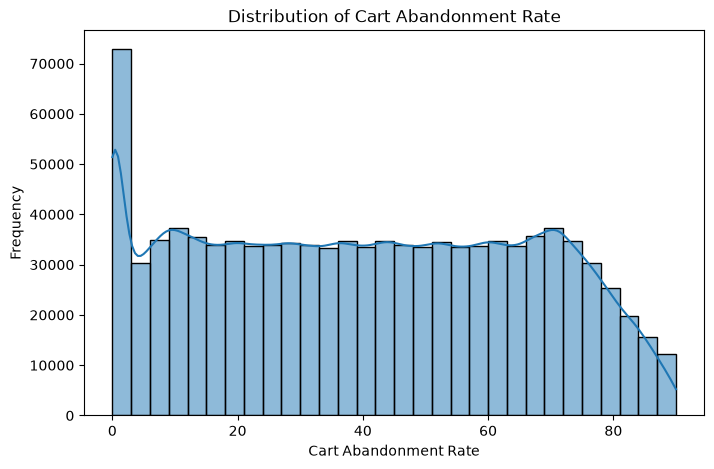

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(df['cart_abandonment_rate'], bins=30, kde=True)
plt.title('Distribution of Cart Abandonment Rate')
plt.xlabel('Cart Abandonment Rate')
plt.ylabel('Frequency')
plt.show()

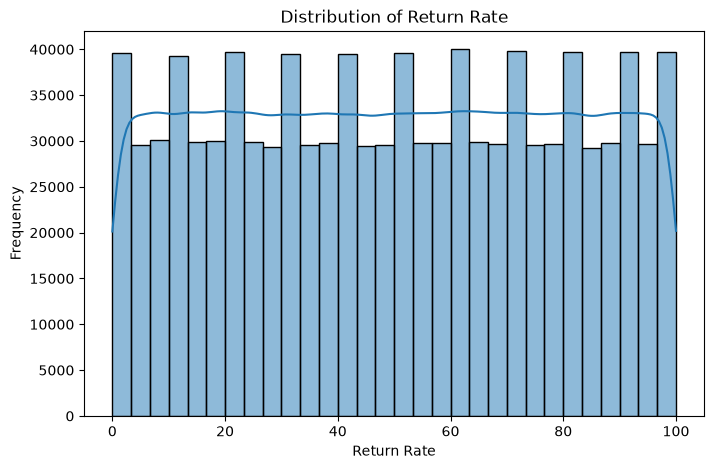

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(df['return_rate'], bins=30, kde=True)
plt.title('Distribution of Return Rate')
plt.xlabel('Return Rate')
plt.ylabel('Frequency')
plt.show()

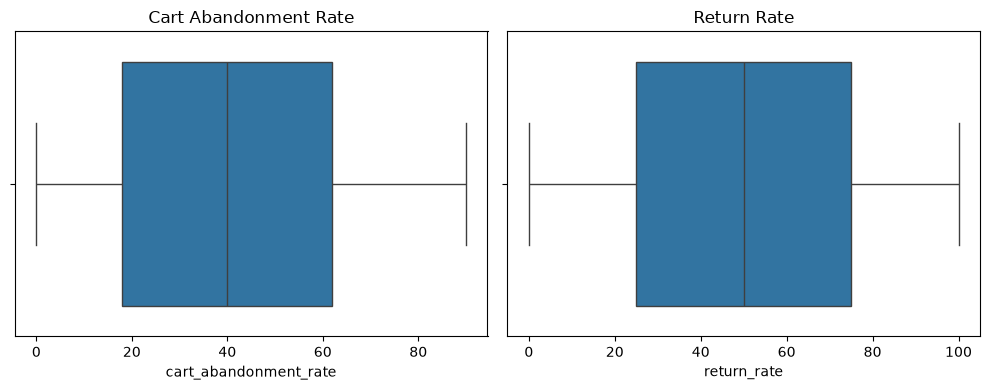

In [32]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['cart_abandonment_rate'])
plt.title('Cart Abandonment Rate')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['return_rate'])
plt.title('Return Rate')

plt.tight_layout()
plt.show()

In [33]:
extreme_users = (df['cart_abandonment_rate'] > 80).sum()
total_users = len(df)

print("Users with cart abandonment above 80%:", extreme_users)
print("Total users:", total_users)
print("Percentage:", round((extreme_users / total_users) * 100, 2), "%")

Users with cart abandonment above 80%: 47708
Total users: 1000000
Percentage: 4.77 %


In [34]:
print("MEAN:")
print(df[['cart_abandonment_rate', 'return_rate']].mean())

print("\nMEDIAN:")
print(df[['cart_abandonment_rate', 'return_rate']].median())

MEAN:
cart_abandonment_rate    40.212257
return_rate              50.004949
dtype: float64

MEDIAN:
cart_abandonment_rate    40.0
return_rate              50.0
dtype: float64


### Conclusion

- Average cart abandonment rate is **40.21%**, while the average return rate is **50.00%**.
- Both distributions are approximately symmetrical, with negligible skewness.
- **4.77% of users (47,708)** have cart abandonment rates above 80%.
- Overall, most users show moderate shopping friction, while a small proportion experience extremely high cart abandonment.

### 1.4 Demographic Analysis

- Examine the distribution of users across categorical demographic variables.
- Identify the dominant device types, countries, education levels, and employment statuses.
- Understand the most common demographic segments within the dataset.

In [35]:
df['device_type'].value_counts()

device_type
Mobile     600247
Desktop    299845
Tablet      99908
Name: count, dtype: int64

In [36]:
df['country'].value_counts()

country
Brazil       100476
Canada       100357
China        100190
Germany      100097
USA           99996
France        99992
Australia     99974
India         99899
UK            99875
Japan         99144
Name: count, dtype: int64

In [37]:
df['education_level'].value_counts()

education_level
Bachelor            299953
High School         299391
Associate Degree    200989
Master              149699
PhD                  49968
Name: count, dtype: int64

In [38]:
df['employment_status'].value_counts()

employment_status
Retired          200246
Unemployed       200225
Employed         199988
Student          199949
Self-employed    199592
Name: count, dtype: int64

In [39]:
for col in ['device_type', 'country', 'education_level', 'employment_status']:
    print(f"\n{col.upper()}")
    print((df[col].value_counts(normalize=True) * 100).round(2))


DEVICE_TYPE
device_type
Mobile     60.02
Desktop    29.98
Tablet      9.99
Name: proportion, dtype: float64

COUNTRY
country
Brazil       10.05
Canada       10.04
China        10.02
Germany      10.01
USA          10.00
France       10.00
Australia    10.00
India         9.99
UK            9.99
Japan         9.91
Name: proportion, dtype: float64

EDUCATION_LEVEL
education_level
Bachelor            30.00
High School         29.94
Associate Degree    20.10
Master              14.97
PhD                  5.00
Name: proportion, dtype: float64

EMPLOYMENT_STATUS
employment_status
Retired          20.02
Unemployed       20.02
Employed         20.00
Student          19.99
Self-employed    19.96
Name: proportion, dtype: float64


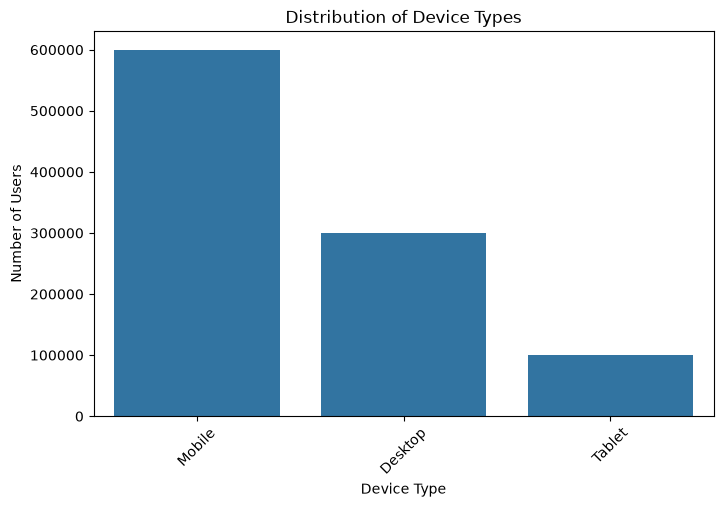

In [40]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='device_type', order=df['device_type'].value_counts().index)
plt.title('Distribution of Device Types')
plt.xlabel('Device Type')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

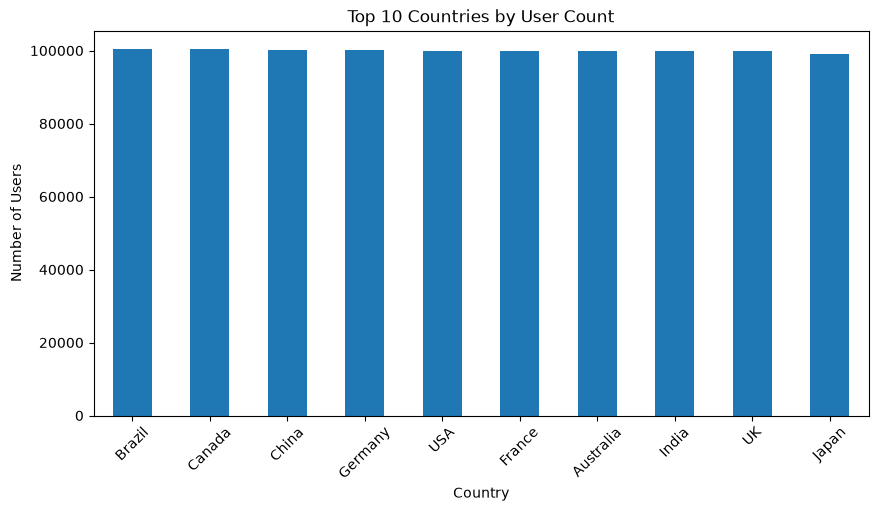

In [41]:
plt.figure(figsize=(10, 5))
df['country'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Countries by User Count')
plt.xlabel('Country')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

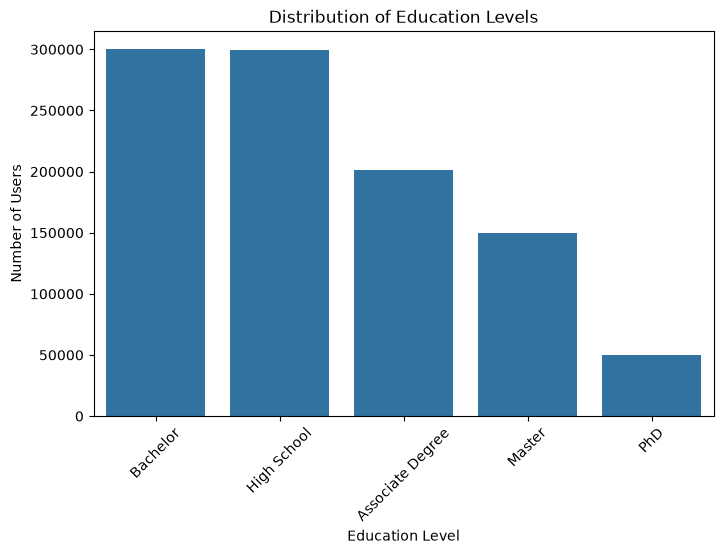

In [42]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='education_level', order=df['education_level'].value_counts().index)
plt.title('Distribution of Education Levels')
plt.xlabel('Education Level')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

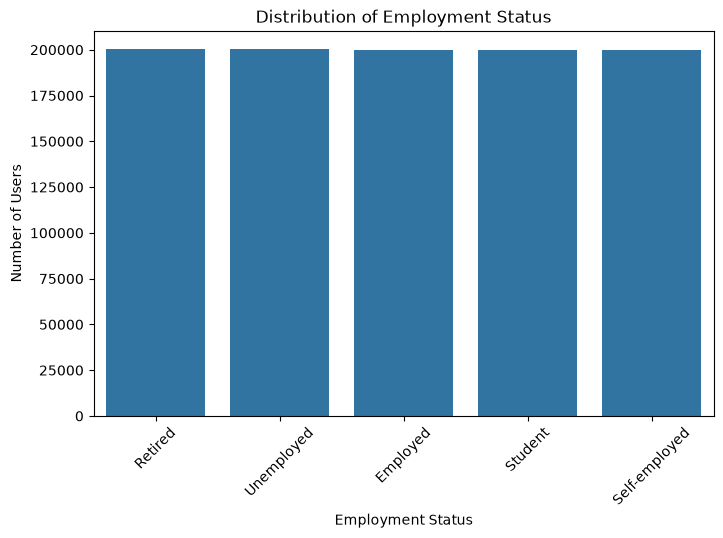

In [43]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='employment_status', order=df['employment_status'].value_counts().index)
plt.title('Distribution of Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

In [44]:
columns = ['device_type', 'country', 'education_level', 'employment_status']

for col in columns:
    dominant = df[col].value_counts().idxmax()
    count = df[col].value_counts().max()
    percentage = (count / len(df)) * 100

    print(f"{col}: {dominant} ({count} users, {percentage:.2f}%)")

device_type: Mobile (600247 users, 60.02%)
country: Brazil (100476 users, 10.05%)
education_level: Bachelor (299953 users, 30.00%)
employment_status: Retired (200246 users, 20.02%)


### Conclusion

- **Mobile** is the dominant device type, accounting for 60.02% of users.
- **Brazil** has the highest country representation at 10.05%.
- **Bachelor's degree** holders form the largest education group at 30.00%.
- Employment status is almost evenly distributed, with each category representing approximately 20% of users.
- Overall, the dataset shows diverse demographics with a clear preference for mobile devices.

# 1. Bivariate Analysis